# Q1D | Train Linear Regression

> *Train a Linear Regression model using the training data with four-fold cross-validation and with appropriate evaluation metric. Do this with a closed-form solution (using the Normal Equation or SVD) and with SGD. Then focus on SGD and perform Ridge, Lasso and Elastic Net regularization: try three values of penalty term and describe its impact. Explore the impact of other hyperparameters of your choice, such as learning rate (no need for grid search). Describe your findings. Select the best-performing regularization set of hyperparameters and train that model on the entire training dataset. For SGD, display the training and validation loss as a function of training epochs for the selected model. (Hint: In scikit-learn, max_iter counts epochs (full passes over the training set). To plot training/validation loss by epoch with SGDRegressor, set max_iter=1 and warm_start=True, then call fit(...) in a loop; after each call (each epoch), compute and record Train and Validation RMSE). Ensure reproducibility by using a seed.*

---

#### IMPORTANT

This notebook uses only the `train` dataset, so no modeling decision is influenced by the test data (`data snooping`). Every model below is fit and scored on the training rows only.

# Answer Summary

**Setup:** every model is one pipeline scored with 4-fold cross validation repeated over 5 seeds (20 folds), on the same validation rows. The metric is rmse, in `Life Ladder` units. A model only counts as better when its rmse gain is more than 1 SE of the per-fold differences, and ties go to the simpler model. Every `random_state` is set to 42.

**Closed form, SGD and the selected model**

| Model | rmse | train rmse | Against the row above |
|---|---|---|---|
| Dummy (always the mean) | 1.1287 | 1.1278 | |
| Closed form, 8 attributes as stored | 0.5458 | 0.5414 | better |
| Closed form, selected features | 0.5160 | 0.5121 | better |
| SGD, no penalty | 0.5164 | 0.5125 | tie |
| Ridge SGD, `alpha=0.001`, `eta0=0.01` (selected) | 0.5164 | 0.5125 | tie |

train rmse is the same model scored on its own training rows.

- **The gain comes from the feature set.** Q1C's shapes for Log GDP (two hinges), Healthy life expectancy (a hinge) and Social support (Yeo-Johnson) hold up with the other attributes in the model, and Generosity and Negative affect can be dropped. Filling the 185 incomplete rows with an imputer did not help, so they are dropped.
- **SGD reaches the same fit as closed form,** with every coefficient within 0.015.
- **Regularization does not help.** At `alpha` 0.001 all three penalties tie with plain SGD. A larger penalty underfits: at 0.1 rmse rises to 0.5173 for Ridge, 0.5200 for Elastic Net and 0.5420 for Lasso, which also sets one coefficient to exactly 0. Plain SGD's training and validation rmse were already close, so there was no overfitting for a penalty to fix.
- **The learning rate matters more than the penalty.** `eta0=0.01` is the best of the four. 0.001 (0.5223) and 0.1 (0.5239) are worse, and 0.0001 underfits badly (0.7136).
- **The selected model is Ridge at `alpha=0.001`,** the smallest penalty among the tied settings. It is selected because the question asks for a regularized model: it scores the same as plain SGD and closed form. Fit on the 1,374 complete training rows it stops after 8 epochs with a training rmse of 0.5128.
- **The loss by epoch shows no overfitting.** Validation rmse falls from 0.7077 to 0.5192 by epoch 2 and is flat at 0.5165 to 0.5166 from epoch 4 on, just above training rmse (0.5129).

**Carried forward:** the fitted pipeline, saved as `linear_regression.joblib`. It takes the 8 attributes as they are stored, and its cross validated rmse of 0.5164 is the estimate for rows it has not seen.

---

# Imports

In [1]:
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.experimental import enable_iterative_imputer  # noqa: F401 (needed before importing IterativeImputer)
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler

from Q1.consts import *

from utils import (
	read_csv_to_df,
	PLOTTING,
	SCORING,
	FEATURES,
	PIPELINES,
)

# Fetch Data

In [2]:
train_df = read_csv_to_df(path=TRAIN_PATH)

# Setup

## Rows and Folds

In [3]:
ATTRIBUTES = [column["col"] for key, column in COLUMNS.items() if key != "LL"]

X = train_df[ATTRIBUTES]
y = train_df[TARGET]

# rows with no missing attribute: the only rows used for validation, and for training unless a pipeline imputes
complete = X.notna().all(axis=1)
X_complete = X[complete]
y_complete = y[complete]

FOLDS = PIPELINES.make_folds(X, seeds=SEEDS)

print(f"rows: {len(X)} | complete: {complete.sum()} | incomplete: {(~complete).sum()}")
print(f"folds: {len(FOLDS)}")

rows: 1559 | complete: 1374 | incomplete: 185
folds: 20


## Shapes

In [4]:
GDP = COLUMNS["LGDP"]["col"]
SOCIAL = COLUMNS["SS"]["col"]
LIFE_EXP = COLUMNS["HLEAB"]["col"]
FREEDOM = COLUMNS["FTMLC"]["col"]
GENEROSITY = COLUMNS["G"]["col"]
CORRUPTION = COLUMNS["POC"]["col"]
POS_AFFECT = COLUMNS["PA"]["col"]
NEG_AFFECT = COLUMNS["NA"]["col"]

# "shape" is the shape Q1C carried forward for each attribute. Any other name is an alternative Q1C also carried forward.
#   HighHinge:                [max(0, x - t)]
#   HighHinge(keep_raw=True): [x, max(0, x - t)]
#   Indicator:                [1 if x < t else 0]
#   Indicator(keep_raw=True): [x, 1 if x < t else 0]
#   PowerTransformer:         [YJ(x)], Yeo-Johnson with its power fit on the training rows, then standardized
SHAPES = {
	GDP: {
		"shape": [FEATURES.HighHinge(t=10.3, keep_raw=True), FEATURES.HighHinge(t=10.9)],
		"indicator": FEATURES.Indicator(t=10.4, keep_raw=True),
	},
	SOCIAL: {
		"shape": FEATURES.HighHinge(t=0.84, keep_raw=True),
		"yeo-johnson": PowerTransformer(method="yeo-johnson"),
	},
	LIFE_EXP: {"shape": FEATURES.HighHinge(t=57.5)},
	FREEDOM: {"shape": FEATURES.HighHinge(t=0.80, keep_raw=True)},
	GENEROSITY: {"shape": FEATURES.Indicator(t=0.087)},
	CORRUPTION: {"shape": FEATURES.Indicator(t=0.58, keep_raw=True)},
	POS_AFFECT: {"shape": FEATURES.Indicator(t=0.749, keep_raw=True)},
	NEG_AFFECT: {"shape": FEATURES.HighHinge(t=0.20)},
}


def build(choice, estimator, *, scale=False, imputer=None):
	"""One pipeline for a feature choice and a model: (imputer) > features > (scaler) > model.

	Args:
		choice: What each attribute contributes: "raw", "drop" or the name of one of its SHAPES. Attributes left
			out are "raw", so {} is the 8 attributes as they are stored.
		estimator: Final model.
		scale: Standardize the feature columns before the model.
		imputer: Fills missing values before the features are built. None for pipelines given complete rows.
	"""
	return PIPELINES.attribute_pipeline(
		estimator, attributes=ATTRIBUTES, shapes=SHAPES, choice=choice, scale=scale, imputer=imputer,
	)


# the feature columns each attribute's shape builds
shape_columns = {}
for attribute in ATTRIBUTES:
	only_this = {other: "drop" for other in ATTRIBUTES if other != attribute} | {attribute: "shape"}
	features = build(only_this, LinearRegression())["features"].fit(X_complete)
	shape_columns[SHORT_NAMES[attribute]] = ", ".join(features.get_feature_names_out())

with pd.option_context("display.max_colwidth", None):
	display(pd.Series(shape_columns).to_frame("feature columns with the shape"))

,feature columns with the shape
GDP,"Log GDP per capita, Log GDP per capita__hinge_10.3, Log GDP per capita__hinge_10.9"
Social,"Social support, Social support__hinge_0.84"
Life exp,Healthy life expectancy at birth__hinge_57.5
Freedom,"Freedom to make life choices, Freedom to make life choices__hinge_0.8"
Generosity,Generosity__below_0.087
Corruption,"Perceptions of corruption, Perceptions of corruption__below_0.58"
Pos affect,"Positive affect, Positive affect__below_0.749"
Neg affect,Negative affect__hinge_0.2


## Scoring

In [5]:
RESULTS = {}


def score(name, pipeline, *, X=X_complete, y=y_complete):
	"""Score a pipeline on FOLDS and keep its per-fold scores in RESULTS under name.

	Args:
		name: Row label of the model in every table.
		pipeline: Model or pipeline to score.
		X: Rows the pipeline is given. X_complete by default. Pass X (with y) for a pipeline that imputes.
		y: Target values for those rows.
	"""
	RESULTS[name] = PIPELINES.evaluate_pipeline(pipeline, X=X, y=y, folds=FOLDS, return_train_score=True)


def table(names, *, baseline, holm=False):
	"""Results table of the named models, with the noise threshold against baseline.

	Args:
		names: Models to show, each already scored with score.
		baseline: Name of the model the rmse difference is measured against. It must be in names.
		holm: Add the Holm adjusted p and the "significant" verdict.
	"""
	return SCORING.results_df({name: RESULTS[name] for name in names}, baseline=baseline, holm=holm, decimals=4)

# Method

Every model is one `Pipeline` from `build(choice, estimator)`: (imputer), features, (scaler), model. `choice` sets each attribute to `"raw"`, `"drop"` or the name of one of its shapes in `SHAPES`, and every step is fit inside each training fold.

- **Folds:** 4-fold cross validation over the 5 `SEEDS`, 20 folds, built once and used by every model. Validation folds hold complete rows only, so every model is scored on the same rows.
- **Rows:** a model given `X_complete` trains on complete rows only. A model with an imputer is given `X` and also trains on the incomplete rows.
- **Metric:** rmse. It is in `Life Ladder` units, counts large misses more than small ones, and is the squared error a linear regression minimizes. mae and r2 are reported next to it, and `train rmse mean` is the same model scored on its own training rows.
- **Shapes:** `SHAPES` holds the shape Q1C carried forward for each attribute (`"shape"`) and its alternative for two of them, with thresholds fixed at Q1B's values (Log GDP's pair is the one Q1C's search picked most often). Those thresholds were found on all the training rows, so a shape's gain is slightly optimistic.
- **Scaling:** SGD models standardize the feature columns. Closed form does not need it.
- **Seed:** the folds come from `SEEDS`, and every `random_state` in a pipeline is set to 42 before it is fit, so a rerun gives the same numbers.

**Noise threshold (Δrmse vs the baseline)**

- Δ is the mean of the per-fold rmse differences d (model minus baseline). Negative means lower error than the baseline.
- The folds share most of their training rows, so the SE of Δ uses the Nadeau and Bengio correction: `SE = sqrt(var(d) · (1/folds + n_test/n_train))`. `Δ / SE` is the corrected t statistic and `p` its one-sided p-value.
- `verdict`:
  - **within noise:** Δ is within 1 SE of 0.
  - **candidate:** Δ is below -1 SE.
  - **worse:** Δ is above +1 SE.
  - **significant** (tables with `p (Holm)` only): the Holm adjusted p is below 0.05, adjusted over that table's rows.

**Decisions**

- **Ties go to the simpler model.** A row that adds something (a column, an imputer, a penalty) is kept only if it is **candidate** or **significant**. A row that removes something is kept unless it is **worse**.
- **Each section's choice is the next section's baseline.**

# Baselines

A model that always predicts the mean `Life Ladder`, then closed form linear regression on the 8 attributes as they are stored.

## Dummy Regressor

In [6]:
score("Dummy", DummyRegressor(strategy="mean"))
display(table(["Dummy"], baseline="Dummy"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs Dummy,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
Dummy,1.1287,0.0294,1.1278,0.9357,0.0263,-0.0044,0.0056,0.0,NaN,NaN,NaN,baseline,20


## Closed Form Linear Regression

`LinearRegression` solves the least squares problem in closed form (scikit-learn uses an SVD based solver): one direct solve, with no iterations and no learning rate.

In [7]:
score("Closed form, 8 raw", build({}, LinearRegression()))
display(table(["Dummy", "Closed form, 8 raw"], baseline="Dummy"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs Dummy,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"Closed form, 8 raw",0.5458,0.0244,0.5414,0.4217,0.0180,0.7646,0.0201,-0.5829,0.0195,-29.9278,0.0,candidate,20
Dummy,1.1287,0.0294,1.1278,0.9357,0.0263,-0.0044,0.0056,0.0000,NaN,NaN,NaN,baseline,20


## Results

- **Closed form on the 8 attributes is far better than predicting the mean.** rmse falls from 1.1287 to 0.5458 (Δ / SE -29.9), and r2 rises to 0.7646.
- **It is not overfitting.** Its rmse on its own training rows (0.5414) is close to its validation rmse (0.5458).

**Carry forward**

- **Closed form, 8 raw** (rmse 0.5458), as the baseline for the Feature Set section.

# Feature Set

Which rows and which feature columns the model is given. Every model in this section is closed form `LinearRegression`, which has no learning rate or seed to add noise to the comparison.

## Missing Rows

Dropping the incomplete rows (the baseline, `Closed form, 8 raw`) against keeping them in training with one of four imputers:

- **median:** each attribute's median, Q1B's suggestion.
- **median + indicator:** the median, plus a 0/1 column for each attribute with missing values, marking the rows that were filled.
- **KNN:** the mean of the 5 most similar rows.
- **iterative:** each attribute with missing values is predicted from the other attributes.

`train rmse mean` is not comparable across these rows: the imputed runs are scored on more training rows, filled values included.

In [8]:
IMPUTERS = {
	"Impute: median": SimpleImputer(strategy="median"),
	"Impute: median + indicator": SimpleImputer(strategy="median", add_indicator=True),
	# KNN measures the distance between rows, so the attributes are standardized first. The model is then fit on
	# the standardized attributes, which gives closed form the same predictions.
	"Impute: KNN": Pipeline([("scale", StandardScaler()), ("knn", KNNImputer(n_neighbors=5))]),
	"Impute: iterative": IterativeImputer(),
}

for name, imputer in IMPUTERS.items():
	score(name, build({}, LinearRegression(), imputer=imputer), X=X, y=y)

# training rows per fold: the imputed runs also train on the incomplete rows
print(f"training rows per fold, incomplete rows dropped: {RESULTS['Closed form, 8 raw']['n_train'].min()} to {RESULTS['Closed form, 8 raw']['n_train'].max()}")
print(f"training rows per fold, incomplete rows imputed: {RESULTS['Impute: median']['n_train'].min()} to {RESULTS['Impute: median']['n_train'].max()}")

display(table(["Closed form, 8 raw", *IMPUTERS], baseline="Closed form, 8 raw", holm=True))

training rows per fold, incomplete rows dropped: 1030 to 1031
training rows per fold, incomplete rows imputed: 1215 to 1216


,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs Closed form, 8 raw",Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,,
"Closed form, 8 raw",0.5458,0.0244,0.5414,0.4217,0.0180,0.7646,0.0201,0.0000,NaN,NaN,NaN,NaN,baseline,20
Impute: KNN,0.5461,0.0242,0.5453,0.4241,0.0185,0.7644,0.0196,0.0003,0.0013,0.2693,0.6047,1.0,within noise,20
Impute: median + indicator,0.5462,0.0241,0.5365,0.4235,0.0179,0.7643,0.0196,0.0004,0.0014,0.2915,0.6131,1.0,within noise,20
Impute: median,0.5463,0.0239,0.5456,0.4234,0.0180,0.7642,0.0196,0.0005,0.0015,0.3378,0.6304,1.0,within noise,20
Impute: iterative,0.5464,0.0241,0.5474,0.4244,0.0184,0.7642,0.0195,0.0006,0.0014,0.4468,0.6700,1.0,within noise,20


### Results

- **Keeping the incomplete rows does not help.** All four imputers are within noise of dropping them: rmse 0.5461 to 0.5464 against 0.5458, and every change (0.0003 to 0.0006) is smaller than its SE (0.0013 to 0.0015).
- **More training rows do not lower the error.** The imputed runs train on 1,215 to 1,216 rows per fold against 1,030 to 1,031.

**Carry forward**

- **Dropping the incomplete rows.** The simpler model wins the tie, so every model below is given `X_complete` and no imputer.

## Shapes, One at a Time

Each row changes one attribute to its shape from `SHAPES` and leaves the other seven as they are stored, so a gain here is one that holds with the other attributes in the model.

In [9]:
ONE_SHAPE = {f"Shape: {SHORT_NAMES[attribute]}": {attribute: "shape"} for attribute in ATTRIBUTES}

for name, choice in ONE_SHAPE.items():
	score(name, build(choice, LinearRegression()))

display(table(["Closed form, 8 raw", *ONE_SHAPE], baseline="Closed form, 8 raw", holm=True))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs Closed form, 8 raw",Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,,
Shape: Life exp,0.5285,0.0226,0.5241,0.4100,0.0164,0.7794,0.0181,-0.0173,0.0035,-4.9432,0.0000,0.0003,significant,20
Shape: GDP,0.5307,0.0232,0.5257,0.4050,0.0172,0.7775,0.0190,-0.0151,0.0028,-5.3893,0.0000,0.0001,significant,20
Shape: Social,0.5354,0.0224,0.5304,0.4145,0.0166,0.7735,0.0189,-0.0103,0.0035,-2.9695,0.0039,0.0236,significant,20
Shape: Freedom,0.5454,0.0241,0.5408,0.4210,0.0179,0.7649,0.0199,-0.0003,0.0006,-0.5883,0.2816,1.0000,within noise,20
"Closed form, 8 raw",0.5458,0.0244,0.5414,0.4217,0.0180,0.7646,0.0201,0.0000,NaN,NaN,NaN,NaN,baseline,20
Shape: Neg affect,0.5458,0.0245,0.5415,0.4219,0.0181,0.7646,0.0202,0.0000,0.0003,0.0629,0.5247,1.0000,within noise,20
Shape: Pos affect,0.5459,0.0244,0.5405,0.4217,0.0179,0.7646,0.0199,0.0001,0.0012,0.0793,0.5312,1.0000,within noise,20
Shape: Corruption,0.5462,0.0243,0.5411,0.4218,0.0179,0.7642,0.0201,0.0005,0.0008,0.6137,0.7267,1.0000,within noise,20
Shape: Generosity,0.5472,0.0245,0.5424,0.4208,0.0176,0.7634,0.0202,0.0014,0.0010,1.3938,0.9103,1.0000,worse,20


### Results

- **Three shapes still help with the other attributes in the model.** Healthy life expectancy (rmse 0.5285), Log GDP (0.5307) and Social support (0.5354) are all significant against 0.5458.
- **The other five shapes add nothing here.** Freedom, Negative affect, Positive affect and Corruption are within noise (changes of -0.0003 to 0.0005), and Generosity's indicator is worse than its raw column (0.5472).

**Carry forward**

- **The shapes for Healthy life expectancy, Log GDP and Social support,** to be combined in one model.

**Ignore**

- **The other five shapes.** Those attributes stay as they are stored.

## Combined

The three shapes that won on their own, in one model: `3 shapes` changes Log GDP, Healthy life expectancy and Social support to their shapes and leaves the other five attributes as they are stored.

In [10]:
THREE_SHAPES = {GDP: "shape", LIFE_EXP: "shape", SOCIAL: "shape"}

score("3 shapes", build(THREE_SHAPES, LinearRegression()))
display(table(["Closed form, 8 raw", "3 shapes"], baseline="Closed form, 8 raw"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs Closed form, 8 raw",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
3 shapes,0.5160,0.0218,0.5106,0.3958,0.0158,0.7896,0.0179,-0.0298,0.0057,-5.1922,0.0,candidate,20
"Closed form, 8 raw",0.5458,0.0244,0.5414,0.4217,0.0180,0.7646,0.0201,0.0000,NaN,NaN,NaN,baseline,20


### One Shape Taken Back Out

Each row puts one of the three attributes back to its raw column. A shape earns its place next to the other two if taking it out is **worse**.

In [11]:
WITHOUT_ONE = {
	f"3 shapes, {SHORT_NAMES[attribute]} raw": {**THREE_SHAPES, attribute: "raw"}
	for attribute in THREE_SHAPES
}

for name, choice in WITHOUT_ONE.items():
	score(name, build(choice, LinearRegression()))

display(table(["3 shapes", *WITHOUT_ONE], baseline="3 shapes"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs 3 shapes,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
3 shapes,0.5160,0.0218,0.5106,0.3958,0.0158,0.7896,0.0179,0.0000,NaN,NaN,NaN,baseline,20
"3 shapes, Social raw",0.5199,0.0226,0.5150,0.3987,0.0161,0.7864,0.0182,0.0040,0.0018,2.2420,0.9815,worse,20
"3 shapes, GDP raw",0.5209,0.0212,0.5159,0.4031,0.0155,0.7856,0.0175,0.0050,0.0014,3.5145,0.9988,worse,20
"3 shapes, Life exp raw",0.5259,0.0222,0.5204,0.4021,0.0170,0.7815,0.0186,0.0099,0.0026,3.7938,0.9994,worse,20


### Alternative Shapes

Q1C carried forward a second form for two of the three attributes. Each row swaps one into `3 shapes`:

- **Log GDP, indicator:** `[x, 1 if x < 10.4 else 0]` in place of the two hinges. One column fewer.
- **Social support, Yeo-Johnson:** `[YJ(x)]` in place of `[x, max(0, x - 0.84)]`. One column fewer and no threshold.

Both alternatives are the simpler form.

In [12]:
ALTERNATIVES = {
	"3 shapes, GDP indicator": {**THREE_SHAPES, GDP: "indicator"},
	"3 shapes, Social Yeo-Johnson": {**THREE_SHAPES, SOCIAL: "yeo-johnson"},
}

for name, choice in ALTERNATIVES.items():
	score(name, build(choice, LinearRegression()))

display(table(["3 shapes", *ALTERNATIVES], baseline="3 shapes"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs 3 shapes,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"3 shapes, Social Yeo-Johnson",0.5156,0.0221,0.5108,0.3950,0.0161,0.7899,0.0182,-0.0003,0.0012,-0.2722,0.3942,within noise,20
3 shapes,0.5160,0.0218,0.5106,0.3958,0.0158,0.7896,0.0179,0.0000,NaN,NaN,NaN,baseline,20
"3 shapes, GDP indicator",0.5196,0.0207,0.5142,0.4020,0.0150,0.7867,0.0171,0.0036,0.0013,2.8222,0.9946,worse,20


### Results

- **The three shapes work together.** `3 shapes` lowers rmse from 0.5458 to 0.5160 (Δ / SE -5.19), and its training rmse (0.5106) stays close.
- **Each shape earns its place.** Taking any one back out is worse: 0.5199 without Social support's, 0.5209 without Log GDP's and 0.5259 without Healthy life expectancy's.
- **Log GDP keeps its two hinges.** Its indicator is worse (0.5196, a change of 0.0036 against an SE of 0.0013).
- **Yeo-Johnson ties with Social support's hinge** (0.5156 against 0.5160, within noise), with one column fewer and no threshold.

**Carry forward**

- **Log GDP's two hinges and Healthy life expectancy's hinge.**
- **Yeo-Johnson for Social support,** the simpler form in a tie. `PowerTransformer` also standardizes the column, which does not change a linear model's predictions.

**Ignore**

- **Log GDP's indicator.** It is worse than the two hinges.
- **Social support's raw value plus hinge.** It ties with Yeo-Johnson and needs an extra column and a fixed threshold.

## Drops

Each row removes attributes from the combined model, `3 shapes, Social Yeo-Johnson`:

- **Generosity and Negative affect:** Q1B's top suggestion for both was to drop them.
- **Log GDP or Healthy life expectancy:** Q1C's one redundant pair.

In [13]:
SHAPED = {GDP: "shape", LIFE_EXP: "shape", SOCIAL: "yeo-johnson"}

DROPS = {
	"Drop Generosity": {**SHAPED, GENEROSITY: "drop"},
	"Drop Neg affect": {**SHAPED, NEG_AFFECT: "drop"},
	"Drop Generosity + Neg affect": {**SHAPED, GENEROSITY: "drop", NEG_AFFECT: "drop"},
	"Drop GDP": {**SHAPED, GDP: "drop"},
	"Drop Life exp": {**SHAPED, LIFE_EXP: "drop"},
}

for name, choice in DROPS.items():
	score(name, build(choice, LinearRegression()))

display(table(["3 shapes, Social Yeo-Johnson", *DROPS], baseline="3 shapes, Social Yeo-Johnson"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs 3 shapes, Social Yeo-Johnson",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"3 shapes, Social Yeo-Johnson",0.5156,0.0221,0.5108,0.3950,0.0161,0.7899,0.0182,0.0000,NaN,NaN,NaN,baseline,20
Drop Neg affect,0.5157,0.0225,0.5113,0.3952,0.0164,0.7898,0.0184,0.0000,0.0006,0.0502,0.5198,within noise,20
Drop Generosity,0.5159,0.0219,0.5115,0.3945,0.0158,0.7897,0.0179,0.0002,0.0009,0.2828,0.6098,within noise,20
Drop Generosity + Neg affect,0.5160,0.0224,0.5121,0.3947,0.0161,0.7896,0.0181,0.0004,0.0010,0.3898,0.6495,within noise,20
Drop GDP,0.5365,0.0195,0.5320,0.4163,0.0153,0.7727,0.0166,0.0208,0.0040,5.1414,1.0000,worse,20
Drop Life exp,0.5388,0.0253,0.5345,0.4083,0.0208,0.7704,0.0217,0.0232,0.0046,5.0257,1.0000,worse,20


### Results

- **Generosity and Negative affect add nothing.** Dropping either one, or both, is within noise. With both gone rmse is 0.5160 against 0.5156, a change of 0.0004 against an SE of 0.0010.
- **Log GDP and Healthy life expectancy are both needed,** although Q1C found them redundant as a pair. Dropping either one is worse (0.5365 and 0.5388).

**Carry forward**

- **`Drop Generosity + Neg affect`** (rmse 0.5160) as the feature set for every model below: Log GDP's two hinges, Healthy life expectancy's hinge, Yeo-Johnson for Social support, and Freedom, Corruption and Positive affect as they are stored.

**Ignore**

- **Dropping Log GDP or Healthy life expectancy.** Each one carries something the other does not.

# SGD

The same feature set fit by stochastic gradient descent, compared with closed form, then the learning rate.

In [14]:
# the feature set carried forward from the Feature Set section
FEATURE_CHOICE = {GDP: "shape", LIFE_EXP: "shape", SOCIAL: "yeo-johnson", GENEROSITY: "drop", NEG_AFFECT: "drop"}
assert FEATURE_CHOICE == DROPS["Drop Generosity + Neg affect"]

# the closed form model on that feature set, under the name used from here on (nothing is scored again)
RESULTS["Closed form, selected features"] = RESULTS["Drop Generosity + Neg affect"]

## SGD vs Closed Form

`SGDRegressor` with no penalty and scikit-learn's default learning rate (`eta0=0.01`), on standardized feature columns. It reaches its coefficients through repeated small steps, where closed form solves for them directly.

In [15]:
score("SGD", build(FEATURE_CHOICE, SGDRegressor(penalty=None), scale=True))
display(table(["Closed form, selected features", "SGD"], baseline="Closed form, selected features"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs Closed form, selected features",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"Closed form, selected features",0.5160,0.0224,0.5121,0.3947,0.0161,0.7896,0.0181,0.0000,NaN,NaN,NaN,baseline,20
SGD,0.5164,0.0224,0.5125,0.3954,0.0161,0.7893,0.0179,0.0004,0.0006,0.6671,0.7436,within noise,20


In [16]:
# both fit once on all the complete rows, on standardized columns so the coefficients are comparable
closed_form_fit = build(FEATURE_CHOICE, LinearRegression(), scale=True).fit(X_complete, y_complete)
sgd_fit = PIPELINES.seed_pipeline(build(FEATURE_CHOICE, SGDRegressor(penalty=None), scale=True)).fit(X_complete, y_complete)

coefficients = pd.DataFrame(
	{"closed form": closed_form_fit["model"].coef_, "SGD": sgd_fit["model"].coef_},
	index=closed_form_fit[:-1].get_feature_names_out(),
)
coefficients["difference"] = coefficients["SGD"] - coefficients["closed form"]

print(f"SGD epochs run: {sgd_fit['model'].n_iter_}")
display(coefficients.round(4))

SGD epochs run: 8


,closed form,SGD,difference
Log GDP per capita,0.2477,0.2540,0.0063
Log GDP per capita__hinge_10.3,0.1902,0.1754,-0.0148
Log GDP per capita__hinge_10.9,-0.1371,-0.1329,0.0042
Social support,0.2312,0.2294,-0.0017
Healthy life expectancy at birth__hinge_57.5,0.3374,0.3338,-0.0036
Freedom to make life choices,0.0540,0.0511,-0.0029
Perceptions of corruption,-0.0522,-0.0568,-0.0046
Positive affect,0.2288,0.2287,-0.0001


### Results

- **SGD reaches the same fit as closed form.** Its rmse is 0.5164 against 0.5160, a change of 0.0004 against an SE of 0.0006, and its training rmse is as close (0.5125 against 0.5121).
- **The coefficients agree.** After 8 epochs every SGD coefficient is within 0.015 of closed form's. The largest gap is on Log GDP's first hinge (-0.0148).

**Carry forward**

- **`SGD`** (rmse 0.5164) as the baseline for the learning rate and the penalties, since the question focuses on SGD from here. Closed form stays the simpler model with the same score.

## Learning Rate

`eta0` is the initial learning rate, the size of the first steps. Each row changes only `eta0`, with the penalty still off. `SGD` already uses 0.01, scikit-learn's default, so it is the baseline and the 0.01 row.

In [17]:
ETA0S = {f"SGD, eta0={eta0}": eta0 for eta0 in LEARNING_RATES if eta0 != 0.01}

for name, eta0 in ETA0S.items():
	score(name, build(FEATURE_CHOICE, SGDRegressor(penalty=None, eta0=eta0), scale=True))

display(table(["SGD", *ETA0S], baseline="SGD"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs SGD,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
SGD,0.5164,0.0224,0.5125,0.3954,0.0161,0.7893,0.0179,0.0000,NaN,NaN,NaN,baseline,20
"SGD, eta0=0.001",0.5223,0.0216,0.5194,0.4022,0.0153,0.7845,0.0175,0.0059,0.0024,2.5000,0.9891,worse,20
"SGD, eta0=0.1",0.5239,0.0250,0.5215,0.4012,0.0211,0.7831,0.0208,0.0075,0.0073,1.0280,0.8416,worse,20
"SGD, eta0=0.0001",0.7136,0.0198,0.7121,0.5944,0.0201,0.5978,0.0249,0.1972,0.0119,16.5207,1.0000,worse,20


In [18]:
# epochs each learning rate runs before SGD stops, fit once on all the complete rows
epochs_run = {}
for eta0 in LEARNING_RATES:
	fitted = PIPELINES.seed_pipeline(build(FEATURE_CHOICE, SGDRegressor(penalty=None, eta0=eta0), scale=True)).fit(X_complete, y_complete)
	epochs_run[eta0] = fitted["model"].n_iter_

display(pd.Series(epochs_run).rename_axis("eta0").to_frame("epochs run"))

,epochs run
eta0,
0.0001,372
0.0010,37
0.0100,8
0.1000,11


### Results

- **0.01 is the best of the four.** Every other `eta0` is worse than the baseline.
- **Too small underfits.** At 0.0001 rmse is 0.7136, with its training rmse just as high (0.7121), although a fit on all the complete rows runs 372 epochs before it stops. At 0.001 rmse is 0.5223 and that fit runs 37 epochs.
- **Too large is less stable.** At 0.1 rmse is 0.5239 and varies the most from fold to fold (sd 0.0250, against 0.0224 for the baseline), so its change (0.0075) is only just above its SE (0.0073).

**Carry forward**

- **`eta0=0.01`** for every penalty run.

**Ignore**

- **The other three learning rates.**

# Regularization

A penalty adds the size of the coefficients to the loss, which pulls them toward 0. `alpha` sets its strength.

- **Ridge** (`l2`): the sum of the squared coefficients.
- **Lasso** (`l1`): the sum of their absolute values, which can set a coefficient to exactly 0.
- **Elastic Net:** a mix of the two, at scikit-learn's default `l1_ratio=0.15`.

Each row changes only the penalty and its `alpha`, at the three values in `ALPHAS`, with `eta0` at 0.01. The baseline is `SGD`, the same model with no penalty.

In [19]:
PENALTIES = {"Ridge": "l2", "Lasso": "l1", "Elastic Net": "elasticnet"}

# eta0 is left at 0.01, SGDRegressor's default
PENALIZED = {
	f"{name}, alpha={alpha}": SGDRegressor(penalty=penalty, alpha=alpha)
	for name, penalty in PENALTIES.items()
	for alpha in ALPHAS
}

for name, estimator in PENALIZED.items():
	score(name, build(FEATURE_CHOICE, estimator, scale=True))

display(table(["SGD", *PENALIZED], baseline="SGD", holm=True))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs SGD,Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,,
"Ridge, alpha=0.01",0.5164,0.0225,0.5125,0.3953,0.0161,0.7893,0.0179,-0.0000,0.0001,-0.2706,0.3948,1.0,within noise,20
"Ridge, alpha=0.001",0.5164,0.0224,0.5125,0.3954,0.0161,0.7893,0.0179,-0.0000,0.0000,-0.4092,0.3435,1.0,within noise,20
"Elastic Net, alpha=0.001",0.5164,0.0224,0.5125,0.3954,0.0161,0.7893,0.0179,-0.0000,0.0000,-0.0245,0.4904,1.0,within noise,20
SGD,0.5164,0.0224,0.5125,0.3954,0.0161,0.7893,0.0179,0.0000,NaN,NaN,NaN,NaN,baseline,20
"Lasso, alpha=0.001",0.5164,0.0224,0.5125,0.3955,0.0161,0.7893,0.0179,0.0000,0.0001,0.4163,0.6591,1.0,within noise,20
"Elastic Net, alpha=0.01",0.5164,0.0225,0.5126,0.3955,0.0161,0.7893,0.0179,0.0000,0.0002,0.1828,0.5716,1.0,within noise,20
"Lasso, alpha=0.01",0.5173,0.0223,0.5133,0.3970,0.0160,0.7886,0.0175,0.0009,0.0009,1.0361,0.8434,1.0,worse,20
"Ridge, alpha=0.1",0.5173,0.0234,0.5142,0.3961,0.0168,0.7885,0.0182,0.0009,0.0013,0.6960,0.7526,1.0,within noise,20
"Elastic Net, alpha=0.1",0.5200,0.0232,0.5167,0.4007,0.0172,0.7864,0.0178,0.0036,0.0020,1.8439,0.9596,1.0,worse,20


## Coefficients

Each setting fit once on all the complete rows, on standardized feature columns. The last column counts the coefficients that are exactly 0.

In [20]:
penalty_coefficients = {}
for name, estimator in {"SGD": SGDRegressor(penalty=None), **PENALIZED}.items():
	fitted = PIPELINES.seed_pipeline(build(FEATURE_CHOICE, estimator, scale=True)).fit(X_complete, y_complete)
	penalty_coefficients[name] = pd.Series(fitted["model"].coef_, index=fitted[:-1].get_feature_names_out())

penalty_coefficients = pd.DataFrame(penalty_coefficients).T
at_zero = (penalty_coefficients == 0).sum(axis=1)
penalty_coefficients = penalty_coefficients.round(4)
penalty_coefficients["coefficients at 0"] = at_zero

display(penalty_coefficients)

,Log GDP per capita,Log GDP per capita__hinge_10.3,Log GDP per capita__hinge_10.9,Social support,Healthy life expectancy at birth__hinge_57.5,Freedom to make life choices,Perceptions of corruption,Positive affect,coefficients at 0
SGD,0.2540,0.1754,-0.1329,0.2294,0.3338,0.0511,-0.0568,0.2287,0
"Ridge, alpha=0.001",0.2540,0.1750,-0.1325,0.2295,0.3335,0.0514,-0.0568,0.2284,0
"Ridge, alpha=0.01",0.2545,0.1720,-0.1291,0.2298,0.3306,0.0534,-0.0574,0.2261,0
"Ridge, alpha=0.1",0.2548,0.1505,-0.1022,0.2307,0.3073,0.0689,-0.0613,0.2072,0
"Lasso, alpha=0.001",0.2536,0.1723,-0.1296,0.2297,0.3342,0.0510,-0.0565,0.2282,0
"Lasso, alpha=0.01",0.2500,0.1440,-0.1000,0.2325,0.3381,0.0500,-0.0543,0.2245,0
"Lasso, alpha=0.1",0.2196,0.0467,0.0000,0.2306,0.3418,0.0362,-0.0188,0.1818,1
"Elastic Net, alpha=0.001",0.2540,0.1746,-0.1321,0.2295,0.3336,0.0513,-0.0568,0.2284,0
"Elastic Net, alpha=0.01",0.2539,0.1680,-0.1249,0.2302,0.3316,0.0529,-0.0569,0.2258,0
"Elastic Net, alpha=0.1",0.2500,0.1210,-0.0677,0.2328,0.3131,0.0646,-0.0547,0.2041,0


## Results

- **No penalty improves on plain SGD.** No setting is a candidate, and the Holm adjusted p is 1.0 on every row.
- **A small penalty changes nothing.** At `alpha=0.001` all three penalties score 0.5164, the same as `SGD`, and every coefficient is within 0.004 of its `SGD` value.
- **A larger penalty costs more, and Lasso costs the most.** At `alpha=0.1` rmse is 0.5173 for Ridge, 0.5200 for Elastic Net and 0.5420 for Lasso. Lasso is already worse at 0.01 (0.5173).
- **The cost is underfitting.** Training rmse rises with validation rmse (0.5384 and 0.5420 for Lasso at 0.1, against 0.5125 and 0.5164 for `SGD`). `SGD`'s two scores were already close, so there was no overfitting for a penalty to fix.
- **The penalties differ in how they shrink.** At `alpha=0.1` Ridge shrinks some coefficients (ex Healthy life expectancy's hinge from 0.3338 to 0.3073) and sets none to 0. Lasso sets Log GDP's second hinge to exactly 0 and cuts its first hinge from 0.1754 to 0.0467. Elastic Net sits between the two on both hinges.

**Carry forward**

- **The five settings that tie with `SGD` at 0.5164:** Ridge and Elastic Net at 0.001 and 0.01, and Lasso at 0.001. The selected model is one of them.

**Ignore**

- **Every setting at `alpha=0.1`, and Lasso at 0.01.** They score above the rest, three of the four by more than the noise threshold.

# Selected Model

The best-performing regularized setting, trained on every complete training row, with its training and validation loss by epoch.

## Selection

Five regularized settings tie with `SGD` at four decimals, so the table below shows them at six. Among tied settings the smaller penalty wins, as the model closest to no penalty, which leaves the three at `alpha=0.001`. Of those, Ridge has the lowest rmse.

In [21]:
TIED = ["Ridge, alpha=0.001", "Elastic Net, alpha=0.001", "Lasso, alpha=0.001", "Ridge, alpha=0.01", "Elastic Net, alpha=0.01"]

display(
	pd.DataFrame({
		"rmse mean": {name: RESULTS[name]["rmse"].mean() for name in ["SGD", *TIED]},
		"Δrmse vs SGD": {name: (RESULTS[name]["rmse"] - RESULTS["SGD"]["rmse"]).mean() for name in ["SGD", *TIED]},
	}).round(6)
)

SELECTED_NAME = "Ridge, alpha=0.001"
SELECTED_MODEL = SGDRegressor(penalty="l2", alpha=0.001, eta0=0.01)

# the selected model is the setting already scored under SELECTED_NAME
assert SELECTED_MODEL.get_params() == PENALIZED[SELECTED_NAME].get_params()

,rmse mean,Δrmse vs SGD
SGD,0.516397,0.000000
"Ridge, alpha=0.001",0.516391,-0.000006
"Elastic Net, alpha=0.001",0.516396,-0.000001
"Lasso, alpha=0.001",0.516431,0.000034
"Ridge, alpha=0.01",0.516358,-0.000039
"Elastic Net, alpha=0.01",0.516436,0.000040


## Every Stage

The selected model next to each earlier stage, measured against closed form on the same feature set.

In [22]:
STAGES = ["Dummy", "Closed form, 8 raw", "Closed form, selected features", "SGD", SELECTED_NAME]
display(table(STAGES, baseline="Closed form, selected features"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs Closed form, selected features",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"Closed form, selected features",0.5160,0.0224,0.5121,0.3947,0.0161,0.7896,0.0181,0.0000,NaN,NaN,NaN,baseline,20
"Ridge, alpha=0.001",0.5164,0.0224,0.5125,0.3954,0.0161,0.7893,0.0179,0.0004,0.0006,0.6557,0.7401,within noise,20
SGD,0.5164,0.0224,0.5125,0.3954,0.0161,0.7893,0.0179,0.0004,0.0006,0.6671,0.7436,within noise,20
"Closed form, 8 raw",0.5458,0.0244,0.5414,0.4217,0.0180,0.7646,0.0201,0.0298,0.0051,5.8144,1.0000,worse,20
Dummy,1.1287,0.0294,1.1278,0.9357,0.0263,-0.0044,0.0056,0.6127,0.0196,31.2586,1.0000,worse,20


## Train on the Entire Training Set

The selected pipeline is fit once on every complete training row. The 185 incomplete rows stay out, as decided in Missing Rows. No rows are held out here, so only a training rmse can be reported.

In [23]:
final_model = PIPELINES.seed_pipeline(build(FEATURE_CHOICE, SELECTED_MODEL, scale=True)).fit(X_complete, y_complete)

final_train_rmse = SCORING.root_mean_squared_error(y_complete, final_model.predict(X_complete))
print(f"rows: {len(X_complete)} | epochs run: {final_model['model'].n_iter_} | train rmse: {final_train_rmse:.4f}")
print(f"intercept: {final_model['model'].intercept_[0]:.4f}")

display(
	pd.Series(final_model["model"].coef_, index=final_model[:-1].get_feature_names_out())
	.to_frame("coefficient (standardized columns)")
	.round(4)
)

rows: 1374 | epochs run: 8 | train rmse: 0.5128
intercept: 5.4544


,coefficient (standardized columns)
Log GDP per capita,0.2540
Log GDP per capita__hinge_10.3,0.1750
Log GDP per capita__hinge_10.9,-0.1325
Social support,0.2295
Healthy life expectancy at birth__hinge_57.5,0.3335
Freedom to make life choices,0.0514
Perceptions of corruption,-0.0568
Positive affect,0.2284


## Training and Validation Loss by Epoch

A validation loss needs rows the model does not train on, so the selected pipeline is trained one epoch at a time on each of the 20 folds. The lines are the mean over the folds.

The model is set to `max_iter=1` and `warm_start=True`, so each `fit` call runs one more epoch from the coefficients of the previous call. Each call also restarts the learning rate at `eta0`, so this is not the same path as the single fit above.

,train rmse,validation rmse
epoch,,
1,0.7066,0.7077
2,0.5166,0.5192
3,0.5136,0.5167
4,0.5132,0.5165
5,0.5130,0.5165
10,0.5129,0.5166
20,0.5129,0.5166
30,0.5129,0.5166


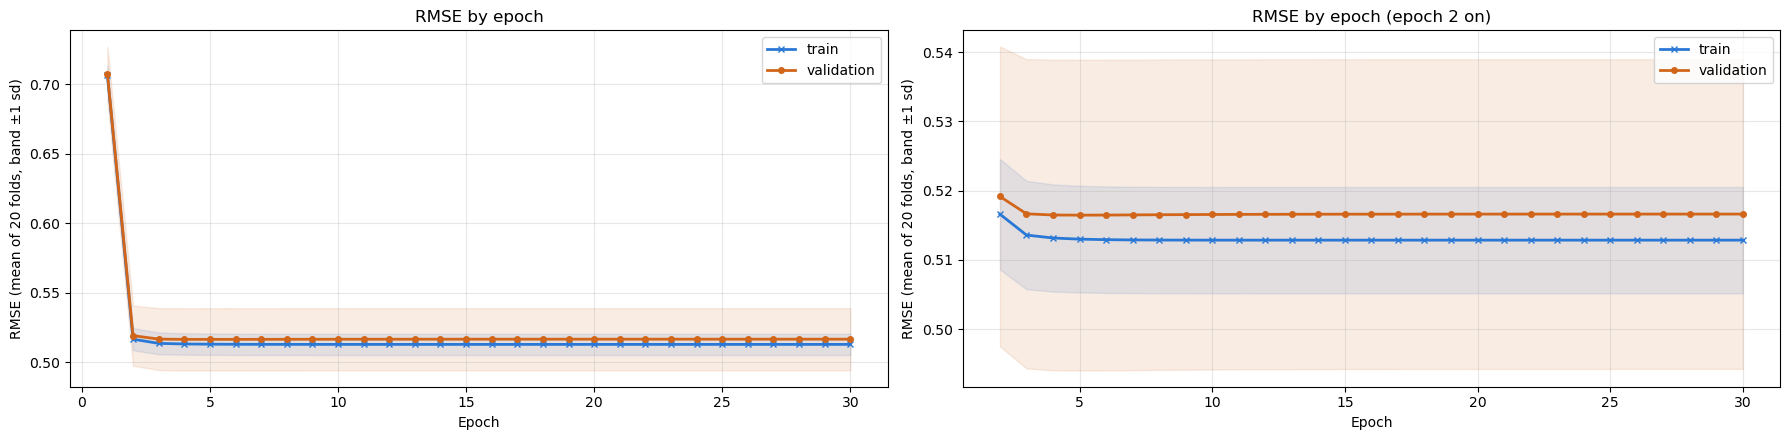

In [24]:
curve = PIPELINES.loss_curve(build(FEATURE_CHOICE, SELECTED_MODEL, scale=True), X=X_complete, y=y_complete, folds=FOLDS, epochs=30)

display(curve.groupby(level="epoch").mean().loc[[1, 2, 3, 4, 5, 10, 20, 30]].round(4))
PLOTTING.loss_curve(curve=curve, zoom_from=2);

## Save the Model

The fitted pipeline takes the 8 attributes as they are stored and builds its own feature columns, so it predicts on new rows with no preprocessing outside it.

In [25]:
MODEL_OUTPUT_DIR.mkdir(exist_ok=True)

model_path = MODEL_OUTPUT_DIR / "linear_regression.joblib"
joblib.dump(final_model, model_path)

reloaded = joblib.load(model_path)
print(f"saved: {model_path.name}")
print(f"reloaded predictions identical: {np.array_equal(reloaded.predict(X_complete), final_model.predict(X_complete))}")

saved: linear_regression.joblib
reloaded predictions identical: True


## Results

- **The selected model is Ridge with `alpha=0.001` and `eta0=0.01`,** at an rmse of 0.5164 over the 20 folds. The tiebreak that picks it is far inside the noise: the five tied settings only differ in the fifth decimal, and Ridge at 0.01 is nominally the lowest (0.516358 against 0.516391).
- **It does not beat the simpler models.** It ties with plain `SGD` (0.5164) and with closed form on the same features (0.5160, a change of 0.0004 against an SE of 0.0006). It is selected because the question asks for the best regularized setting, not because the penalty helps.
- **Fit on all 1,374 complete rows, it behaves like the fold models.** It stops after 8 epochs with a training rmse of 0.5128, against 0.5125 across the folds.
- **The loss curve shows no overfitting.** Almost all the learning happens between epoch 1 and epoch 2, where validation rmse falls from 0.7077 to 0.5192. From epoch 4 on both lines are flat: validation stays at 0.5165 to 0.5166, with training just below it (0.5129 to 0.5132).

**Carry forward**

- **`linear_regression.joblib`,** the fitted pipeline, which reloads with identical predictions. Its cross validated rmse of 0.5164 is the estimate for rows it has not seen.